In [22]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root, "| Files:", len(files))

/kaggle/input | Files: 0
/kaggle/input/datasets | Files: 0
/kaggle/input/datasets/nebalelshobary | Files: 0
/kaggle/input/datasets/nebalelshobary/shoplifting-detection-dataset | Files: 0
/kaggle/input/datasets/nebalelshobary/shoplifting-detection-dataset/non shop lifters | Files: 531
/kaggle/input/datasets/nebalelshobary/shoplifting-detection-dataset/shop lifters | Files: 324


In [23]:
import os
import cv2
import pandas as pd

DATASET_PATH = "/kaggle/input/datasets/nebalelshobary/shoplifting-detection-dataset"

records = []

classes = {
    "non shop lifters": 0,
    "shop lifters": 1
}

for class_name, label in classes.items():

    folder = os.path.join(DATASET_PATH, class_name)

    for filename in os.listdir(folder):

        video_path = os.path.join(folder, filename)

        cap = cv2.VideoCapture(video_path)

        if not cap.isOpened():
            print("Cannot open:", filename)
            continue

        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        fps = cap.get(cv2.CAP_PROP_FPS)

        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

        duration = total_frames / fps if fps > 0 else 0

        records.append({
            "Video": filename,
            "Class": class_name,
            "Label": label,
            "Frames": total_frames,
            "FPS": fps,
            "Duration": duration,
            "Width": width,
            "Height": height
        })

        cap.release()

df = pd.DataFrame(records)

print("Total readable videos:", len(df))

print("\nVideos per class:")
print(df["Class"].value_counts())

print("\nDataset statistics:")
display(df[["Frames", "FPS", "Duration", "Width", "Height"]].describe())

print("\nSample videos:")
display(df.head())

Total readable videos: 855

Videos per class:
Class
non shop lifters    531
shop lifters        324
Name: count, dtype: int64

Dataset statistics:


,Frames,FPS,Duration,Width,Height
count,855.000000,855.000000,855.000000,855.0,855.0
mean,331.419883,24.952784,13.281001,704.0,576.0
std,119.381055,0.090644,4.777120,0.0,0.0
min,75.000000,24.750000,3.000000,704.0,576.0
25%,250.000000,25.000000,10.020202,704.0,576.0
50%,325.000000,25.000000,13.000000,704.0,576.0
75%,396.000000,25.000000,16.000000,704.0,576.0
max,1850.000000,25.000000,74.000000,704.0,576.0



Sample videos:


,Video,Class,Label,Frames,FPS,Duration,Width,Height
0,shop_lifter_n_216.mp4,non shop lifters,0,350,25.0,14.0,704,576
1,shop_lifter_n_98.mp4,non shop lifters,0,275,25.0,11.0,704,576
2,shop_lifter_n_137.mp4,non shop lifters,0,425,25.0,17.0,704,576
3,shop_lifter_n_86_1.mp4,non shop lifters,0,300,25.0,12.0,704,576
4,shop_lifter_n_19_1.mp4,non shop lifters,0,325,25.0,13.0,704,576


## 2. Uniform Temporal Frame Sampling

### Objective
Convert variable-length videos into fixed-length sequences of **16 evenly distributed frames** for the 3D CNN model.

### Methodology
- Identify the total number of frames in each video.
- Generate uniformly spaced frame indices using `numpy.linspace`.
- Decode the selected frames using OpenCV.
- Repeat frame positions when the video contains fewer than 16 frames.
- Preserve chronological order to capture temporal information.

**Expected Output:** A sequence of 16 RGB frames representing the full video duration.

In [24]:
# ============================================================
# STEP 2.— FRAME SAMPLING CONFIGURATION
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

NUM_FRAMES = 16
FRAME_SIZE = (160, 160)
RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)

print("=" * 50)
print("VIDEO PREPROCESSING CONFIGURATION")
print("=" * 50)
print(f"Frames per video : {NUM_FRAMES}")
print(f"Frame resolution : {FRAME_SIZE}")
print(f"Random seed      : {RANDOM_SEED}")
print(f"Resize method    : Aspect Ratio + Padding")
print("=" * 50)

VIDEO PREPROCESSING CONFIGURATION
Frames per video : 16
Frame resolution : (160, 160)
Random seed      : 42
Resize method    : Aspect Ratio + Padding


In [25]:
# ============================================================
# STEP 2.2 — ASPECT-RATIO-PRESERVING FRAME SAMPLING
# ============================================================

def resize_with_padding(frame, target_size=(160, 160)):
    """
    Resize an RGB frame while preserving its aspect ratio.
    Add symmetric black padding to reach the target size.
    """
    target_w, target_h = target_size
    h, w = frame.shape[:2]

    scale = min(target_w / w, target_h / h)

    new_w = max(1, min(target_w, round(w * scale)))
    new_h = max(1, min(target_h, round(h * scale)))

    interpolation = (
        cv2.INTER_AREA if scale < 1
        else cv2.INTER_LINEAR
    )

    resized = cv2.resize(
        frame,
        (new_w, new_h),
        interpolation=interpolation
    )

    pad_left = (target_w - new_w) // 2
    pad_right = target_w - new_w - pad_left

    pad_top = (target_h - new_h) // 2
    pad_bottom = target_h - new_h - pad_top

    padded = cv2.copyMakeBorder(
        resized,
        pad_top,
        pad_bottom,
        pad_left,
        pad_right,
        borderType=cv2.BORDER_CONSTANT,
        value=(0, 0, 0)
    )

    return padded


def sample_video_frames(
    video_path,
    num_frames=NUM_FRAMES,
    frame_size=FRAME_SIZE
):
    """
    Uniformly sample frames across the entire video.

    Returns:
        frames: RGB array with shape (T, H, W, C)
        indices: selected frame positions
    """

    if num_frames <= 0:
        raise ValueError("num_frames must be positive.")

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise ValueError(f"Cannot open video: {video_path}")

    try:
        total_frames = int(
            cap.get(cv2.CAP_PROP_FRAME_COUNT)
        )

        if total_frames <= 0:
            raise ValueError(f"Empty video: {video_path}")

        indices = np.linspace(
            0,
            total_frames - 1,
            num_frames
        ).astype(np.int64)

        frames = []

        for idx in indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
            success, frame = cap.read()

            if not success:
                raise RuntimeError(
                    f"Failed to decode frame {idx}: {video_path}"
                )

            # BGR -> RGB
            frame = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            # Resize while preserving aspect ratio
            frame = resize_with_padding(
                frame,
                target_size=frame_size
            )

            frames.append(frame)

        frames = np.stack(frames, axis=0)

        return frames, indices

    finally:
        cap.release()


print("✅ Frame sampling function updated successfully.")

✅ Frame sampling function updated successfully.


In [26]:
# ============================================================
# STEP 2.3 — FRAME SAMPLING VALIDATION
# ============================================================

test_cases = {
    "Shortest": df.loc[df["Frames"].idxmin()],
    "Median": df.iloc[
        (df["Frames"] - df["Frames"].median()).abs().argmin()
    ],
    "Longest": df.loc[df["Frames"].idxmax()]
}

print("=" * 65)
print("UNIFORM FRAME SAMPLING VALIDATION")
print("=" * 65)

for name, video in test_cases.items():

    video_path = (
        f"{DATASET_PATH}/{video['Class']}/{video['Video']}"
    )

    frames, indices = sample_video_frames(
        video_path,
        num_frames=NUM_FRAMES,
        frame_size=FRAME_SIZE
    )

    expected_shape = (
        NUM_FRAMES,
        FRAME_SIZE[1],
        FRAME_SIZE[0],
        3
    )

    assert frames.shape == expected_shape, \
        "Incorrect output shape"

    assert np.all(np.diff(indices) >= 0), \
        "Frame indices are not ordered"

    assert indices[0] == 0
    assert indices[-1] == video["Frames"] - 1

    print(f"\n{name} Video")
    print("-" * 50)
    print(f"Original frames : {video['Frames']}")
    print(f"Duration        : {video['Duration']:.2f} seconds")
    print(f"Sampled frames  : {len(frames)}")
    print(f"Output shape    : {frames.shape}")
    print(f"Frame indices   : {indices.tolist()}")

print("\n✅ All frame sampling tests passed!")

UNIFORM FRAME SAMPLING VALIDATION

Shortest Video
--------------------------------------------------
Original frames : 75
Duration        : 3.00 seconds
Sampled frames  : 16
Output shape    : (16, 160, 160, 3)
Frame indices   : [0, 4, 9, 14, 19, 24, 29, 34, 39, 44, 49, 54, 59, 64, 69, 74]

Median Video
--------------------------------------------------
Original frames : 325
Duration        : 13.00 seconds
Sampled frames  : 16
Output shape    : (16, 160, 160, 3)
Frame indices   : [0, 21, 43, 64, 86, 108, 129, 151, 172, 194, 216, 237, 259, 280, 302, 324]

Longest Video
--------------------------------------------------
Original frames : 1850
Duration        : 74.00 seconds
Sampled frames  : 16
Output shape    : (16, 160, 160, 3)
Frame indices   : [0, 123, 246, 369, 493, 616, 739, 862, 986, 1109, 1232, 1355, 1479, 1602, 1725, 1849]

✅ All frame sampling tests passed!


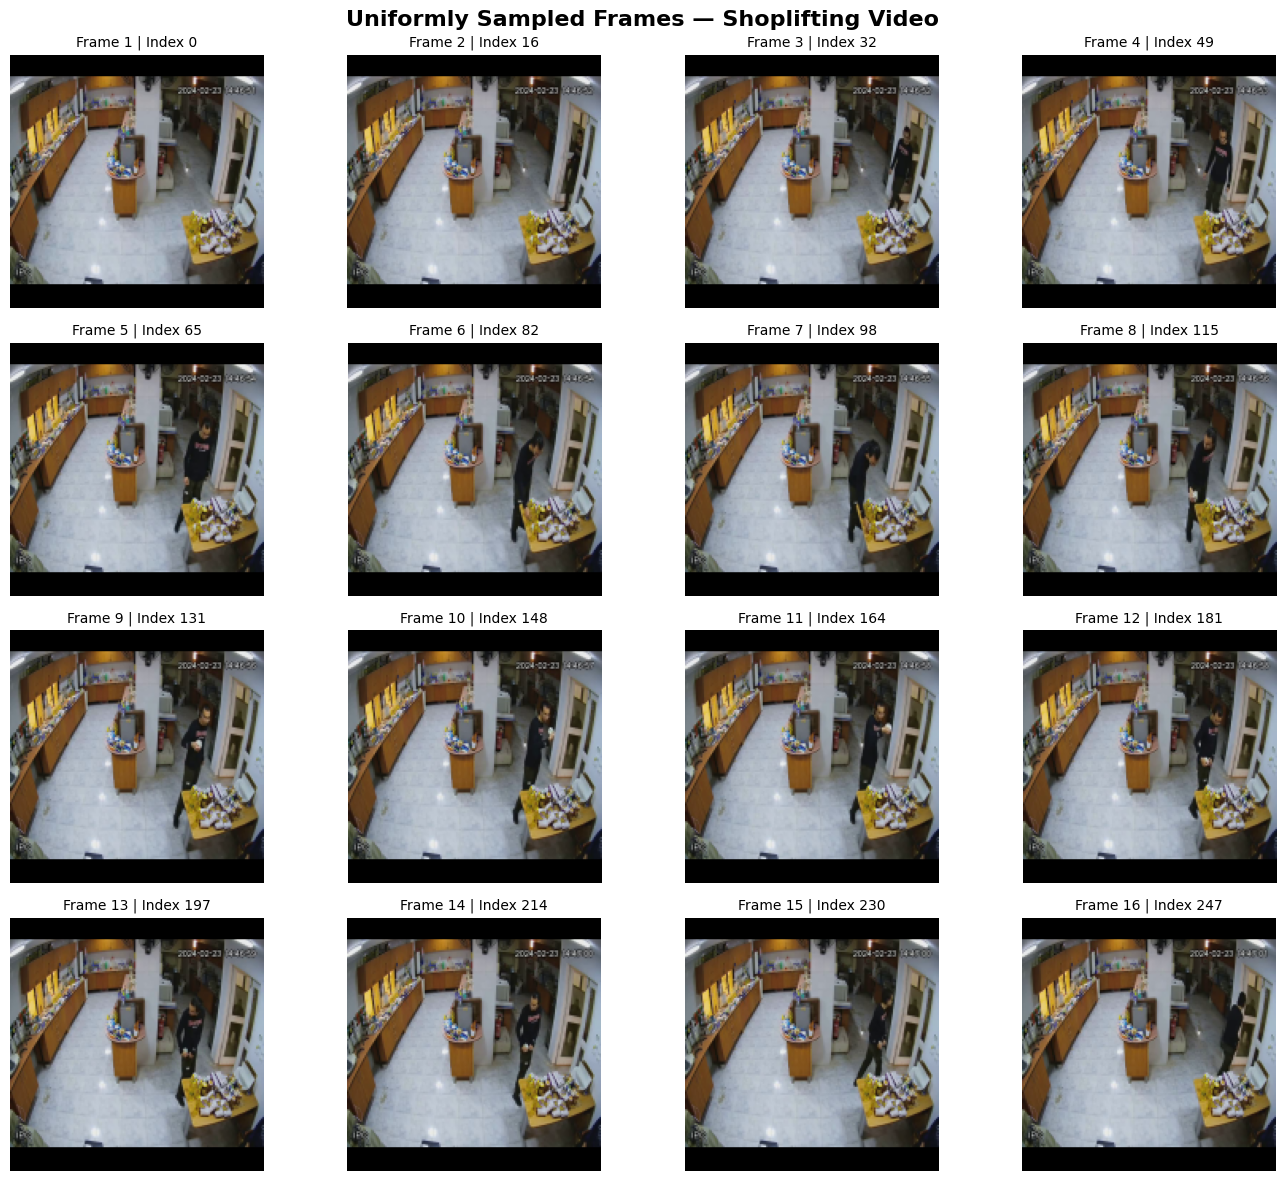

Video: shop_lifter_75.mp4
Original Frames: 248
Sampled Shape: (16, 160, 160, 3)


In [27]:
# ============================================================
# STEP 2.4 — VISUALIZE SAMPLED FRAMES
# ============================================================

sample_row = df[df["Label"] == 1].iloc[0]

video_path = (
    f"{DATASET_PATH}/{sample_row['Class']}/{sample_row['Video']}"
)

frames, indices = sample_video_frames(
    video_path,
    num_frames=NUM_FRAMES,
    frame_size=FRAME_SIZE
)

fig, axes = plt.subplots(
    4, 4, figsize=(14, 12)
)

for i, ax in enumerate(axes.flat):
    ax.imshow(frames[i])

    ax.set_title(
        f"Frame {i+1} | Index {indices[i]}",
        fontsize=10
    )

    ax.axis("off")

plt.suptitle(
    "Uniformly Sampled Frames — Shoplifting Video",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("Video:", sample_row["Video"])
print("Original Frames:", sample_row["Frames"])
print("Sampled Shape:", frames.shape)

## 3. Consistent Spatial Data Augmentation

### Objective
Improve model generalization by applying spatial transformations
consistently across all frames of each video clip.

### Augmentation Techniques
- Random Horizontal Flip
- Random Spatial Crop and Resize
- Random Brightness, Contrast, and Saturation Adjustments

### Temporal Consistency
Augmentation parameters are sampled once per video and applied
identically to every frame within that clip.

### Training Strategy
- Training: Apply random augmentation.
- Validation and Testing: No random augmentation.

**Expected Output:** Augmented clips maintain the same dimensions
and temporal consistency as the original sampled clips.

In [28]:
# ============================================================
# STEP 3.1 — CONSISTENT VIDEO AUGMENTATION
# ============================================================

def augment_video_consistently(
    frames,
    rng=None,
    return_params=False
):
    """
    Apply identical spatial augmentation parameters to
    all frames of a single video.

    Args:
        frames: NumPy array with shape (T, H, W, C).
        rng: Optional NumPy random generator.
        return_params: Return transformation parameters.

    Returns:
        Augmented frames with the original input shape.
    """

    if rng is None:
        rng = np.random.default_rng()

    T, H, W, C = frames.shape

    # Sample augmentation parameters ONCE per video
    flip = rng.random() < 0.5

    crop_scale = rng.uniform(0.90, 1.00)

    crop_h = max(1, int(H * crop_scale))
    crop_w = max(1, int(W * crop_scale))

    top = int(rng.integers(0, H - crop_h + 1))
    left = int(rng.integers(0, W - crop_w + 1))

    brightness = rng.uniform(0.90, 1.10)
    contrast = rng.uniform(0.90, 1.10)
    saturation = rng.uniform(0.90, 1.10)

    augmented_frames = []

    for frame in frames:

        # 1. Apply the same crop
        augmented = frame[
            top:top + crop_h,
            left:left + crop_w
        ]

        augmented = cv2.resize(
            augmented,
            (W, H),
            interpolation=cv2.INTER_LINEAR
        )

        # 2. Apply the same horizontal flip
        if flip:
            augmented = cv2.flip(augmented, 1)

        # 3. Apply the same brightness and contrast
        augmented = augmented.astype(np.float32)

        augmented = (
            (augmented - 127.5) * contrast
            + 127.5
        ) * brightness

        augmented = np.clip(
            augmented, 0, 255
        ).astype(np.uint8)

        # 4. Apply the same saturation adjustment
        hsv = cv2.cvtColor(
            augmented,
            cv2.COLOR_RGB2HSV
        ).astype(np.float32)

        hsv[:, :, 1] *= saturation
        hsv[:, :, 1] = np.clip(
            hsv[:, :, 1], 0, 255
        )

        augmented = cv2.cvtColor(
            hsv.astype(np.uint8),
            cv2.COLOR_HSV2RGB
        )

        augmented_frames.append(augmented)

    augmented_frames = np.stack(
        augmented_frames,
        axis=0
    )

    params = {
        "flip": flip,
        "crop_scale": crop_scale,
        "crop_top": top,
        "crop_left": left,
        "brightness": brightness,
        "contrast": contrast,
        "saturation": saturation
    }

    if return_params:
        return augmented_frames, params

    return augmented_frames


print("✅ Consistent augmentation function defined.")

✅ Consistent augmentation function defined.


In [29]:
# ============================================================
# STEP 3.2 — AUGMENTATION VALIDATION
# ============================================================

rng1 = np.random.default_rng(42)
rng2 = np.random.default_rng(42)

augmented_1, params_1 = augment_video_consistently(
    frames,
    rng=rng1,
    return_params=True
)

augmented_2, params_2 = augment_video_consistently(
    frames,
    rng=rng2,
    return_params=True
)

assert augmented_1.shape == frames.shape
assert augmented_1.dtype == np.uint8

assert np.array_equal(
    augmented_1,
    augmented_2
), "Reproducibility test failed!"

assert params_1 == params_2

print("=" * 55)
print("CONSISTENT AUGMENTATION VALIDATION")
print("=" * 55)

print("Original shape :", frames.shape)
print("Augmented shape:", augmented_1.shape)

print("\nApplied parameters:")
for key, value in params_1.items():
    print(f"{key:15}: {value}")

print("\n✅ Shape validation passed!")
print("✅ Reproducibility validation passed!")
print("✅ Shared augmentation parameters verified!")

CONSISTENT AUGMENTATION VALIDATION
Original shape : (16, 160, 160, 3)
Augmented shape: (16, 160, 160, 3)

Applied parameters:
flip           : False
crop_scale     : 0.9438878439752052
crop_top       : 4
crop_left      : 8
brightness     : 1.0394736058118728
contrast       : 0.9188354695775299
saturation     : 1.0951244703273513

✅ Shape validation passed!
✅ Reproducibility validation passed!
✅ Shared augmentation parameters verified!


## 4. PyTorch Video Dataset

### Objective
Build a custom PyTorch Dataset to prepare video clips for
deep learning-based shoplifting detection.

### Data Processing Pipeline
1. Load the video file and its corresponding label.
2. Uniformly sample 16 frames across the video duration.
3. Resize frames to 160×160 while preserving aspect ratio.
4. Apply consistent spatial augmentation during training only.
5. Normalize pixel values to the [0, 1] range.
6. Convert the frame sequence into a PyTorch tensor.

### Expected Output
- Video tensor shape: (T, C, H, W)
- Label: 0 (Normal) or 1 (Shoplifting)

The Dataset will be compatible with PyTorch DataLoader
and the 3D CNN architecture.

In [30]:
# ============================================================
# STEP 4.1 — CUSTOM PYTORCH VIDEO DATASET
# ============================================================

import torch
from torch.utils.data import Dataset, DataLoader


class ShopliftingVideoDataset(Dataset):
    """
    Custom PyTorch Dataset for binary video classification.

    Processing:
        1. Load and uniformly sample video frames.
        2. Preserve aspect ratio during resizing.
        3. Apply consistent augmentation (training only).
        4. Normalize pixel values.
        5. Convert frames to PyTorch tensors.

    Returns:
        video: Tensor (T, C, H, W)
        label: Tensor containing class index (0 or 1)
    """

    def __init__(
        self,
        dataframe,
        num_frames=NUM_FRAMES,
        frame_size=FRAME_SIZE,
        augment=False
    ):
        self.dataframe = dataframe.reset_index(drop=True)
        self.num_frames = num_frames
        self.frame_size = frame_size
        self.augment = augment

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        video_path = os.path.join(
            DATASET_PATH,
            row["Class"],
            row["Video"]
        )

        label = int(row["Label"])

        # 1. Uniform frame sampling + resizing
        frames, _ = sample_video_frames(
            video_path=video_path,
            num_frames=self.num_frames,
            frame_size=self.frame_size
        )

        # 2. Consistent augmentation (training only)
        if self.augment:
            frames = augment_video_consistently(frames)

        # 3. Convert to float and normalize [0, 1]
        frames = frames.astype(np.float32) / 255.0

        # 4. Convert (T, H, W, C) -> (T, C, H, W)
        frames = np.transpose(frames, (0, 3, 1, 2))
        frames = np.ascontiguousarray(frames)

        video_tensor = torch.from_numpy(frames)

        # 5. Create class label
        label_tensor = torch.tensor(
            label,
            dtype=torch.long
        )

        return video_tensor, label_tensor


print("✅ ShopliftingVideoDataset defined successfully!")

✅ ShopliftingVideoDataset defined successfully!


In [31]:
# ============================================================
# STEP 4.2 — PYTORCH DATASET VALIDATION
# ============================================================

# A small subset for initial testing only
test_subset = df.sample(
    n=4,
    random_state=RANDOM_SEED
).reset_index(drop=True)

test_dataset = ShopliftingVideoDataset(
    dataframe=test_subset,
    num_frames=NUM_FRAMES,
    frame_size=FRAME_SIZE,
    augment=False
)

video_tensor, label_tensor = test_dataset[0]

expected_shape = (
    NUM_FRAMES,
    3,
    FRAME_SIZE[1],
    FRAME_SIZE[0]
)

assert video_tensor.shape == expected_shape
assert video_tensor.dtype == torch.float32

assert 0.0 <= video_tensor.min().item()
assert video_tensor.max().item() <= 1.0

assert label_tensor.item() in [0, 1]

print("=" * 55)
print("PYTORCH DATASET VALIDATION")
print("=" * 55)

print(f"Dataset size     : {len(test_dataset)}")
print(f"Video shape      : {tuple(video_tensor.shape)}")
print(f"Video dtype      : {video_tensor.dtype}")
print(f"Pixel range      : "
      f"[{video_tensor.min():.3f}, "
      f"{video_tensor.max():.3f}]")
print(f"Label            : {label_tensor.item()}")

print("\n✅ All Dataset validation checks passed!")

PYTORCH DATASET VALIDATION
Dataset size     : 4
Video shape      : (16, 3, 160, 160)
Video dtype      : torch.float32
Pixel range      : [0.000, 0.961]
Label            : 0

✅ All Dataset validation checks passed!


In [32]:
# ============================================================
# STEP 4.3 — DATALOADER BATCH VALIDATION
# ============================================================

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0
)

batch_videos, batch_labels = next(iter(test_loader))

expected_shape = (
    2,
    NUM_FRAMES,
    3,
    FRAME_SIZE[1],
    FRAME_SIZE[0]
)

assert batch_videos.shape == expected_shape
assert batch_labels.shape == (2,)
assert batch_videos.dtype == torch.float32

print("=" * 55)
print("DATALOADER VALIDATION")
print("=" * 55)

print("Batch video shape :", tuple(batch_videos.shape))
print("Batch label shape :", tuple(batch_labels.shape))
print("Batch labels      :", batch_labels.tolist())

print("\n✅ DataLoader batch validation passed!")

DATALOADER VALIDATION
Batch video shape : (2, 16, 3, 160, 160)
Batch label shape : (2,)
Batch labels      : [0, 0]

✅ DataLoader batch validation passed!


## 5. Stratified Dataset Splitting

### Objective
Divide the dataset into training, validation, and testing subsets
while preserving the class distribution.

### Split Strategy
- Training Set: 70%
- Validation Set: 15%
- Test Set: 15%

### Methodology
Use stratified sampling to maintain similar proportions of
normal shopping and shoplifting videos in each subset.

### Data Leakage Prevention
The same video file must not appear in more than one subset.
Related clips from the same original recording must also be
kept together whenever their source identity is known.

### Expected Output
Three independent datasets ready for PyTorch DataLoaders.

In [33]:
# ============================================================
# STEP 5.1 — GROUP-AWARE STRATIFIED DATASET SPLITTING
# ============================================================

import os
import re
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold

def extract_source_id(filename):
    """
    Identify suspected related clips based on naming.

    Example:
    shop_lifter_n_86.mp4   -> shop_lifter_n_86
    shop_lifter_n_86_1.mp4 -> shop_lifter_n_86
    """
    name = os.path.splitext(filename)[0]
    match = re.match(r"^(.*_\d+)_\d+$", name)

    return match.group(1) if match else name


df["Source_ID"] = df["Video"].apply(extract_source_id)

# Include class to prevent unrelated cross-class ID collisions.
df["Group_ID"] = df["Class"] + "/" + df["Source_ID"]

# Use 5-fold grouping to obtain approximately 20% per fold.
# Select a test fold near 15%, then a validation fold from
# the remaining data using a second grouped split.

def choose_group_split(data, target_fraction, seed):
    """
    Find a grouped stratified partition near the target size
    and class proportions. No group can cross partitions.
    """
    best = None
    overall_positive_rate = data["Label"].mean()

    for n_splits in [5, 6, 7]:
        splitter = StratifiedGroupKFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=seed
        )

        for train_idx, holdout_idx in splitter.split(
            data,
            data["Label"],
            groups=data["Group_ID"]
        ):
            holdout = data.iloc[holdout_idx]

            size_error = abs(
                len(holdout) / len(data) - target_fraction
            )

            balance_error = abs(
                holdout["Label"].mean()
                - overall_positive_rate
            )

            score = size_error + balance_error

            if best is None or score < best[0]:
                best = (score, train_idx, holdout_idx)

    return best[1], best[2]


# Step 1: Hold out approximately 15% for testing
remaining_idx, test_idx = choose_group_split(
    df,
    target_fraction=0.15,
    seed=RANDOM_SEED
)

remaining_df = df.iloc[remaining_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

# Step 2: Hold out 15% of full data for validation.
# 15/85 of remaining data = approximately 17.65%
train_idx, val_idx = choose_group_split(
    remaining_df,
    target_fraction=0.15 / 0.85,
    seed=RANDOM_SEED + 1
)

train_df = remaining_df.iloc[train_idx].reset_index(drop=True)
val_df = remaining_df.iloc[val_idx].reset_index(drop=True)

print("=" * 60)
print("GROUP-AWARE STRATIFIED DATASET SPLIT")
print("=" * 60)

for name, subset in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name}: {len(subset)} videos")
    print(subset["Class"].value_counts())
    print("Class proportions:")
    print(subset["Label"].value_counts(normalize=True).round(3))

GROUP-AWARE STRATIFIED DATASET SPLIT

Training: 611 videos
Class
non shop lifters    379
shop lifters        232
Name: count, dtype: int64
Class proportions:
Label
0    0.62
1    0.38
Name: proportion, dtype: float64

Validation: 122 videos
Class
non shop lifters    76
shop lifters        46
Name: count, dtype: int64
Class proportions:
Label
0    0.623
1    0.377
Name: proportion, dtype: float64

Testing: 122 videos
Class
non shop lifters    76
shop lifters        46
Name: count, dtype: int64
Class proportions:
Label
0    0.623
1    0.377
Name: proportion, dtype: float64


In [34]:
# ============================================================
# STEP 5.2 — GROUP-AWARE SPLIT VALIDATION
# ============================================================

def get_video_paths(subset):
    return set(
        zip(subset["Class"], subset["Video"])
    )


def get_source_groups(subset):
    return set(subset["Group_ID"])


# ------------------------------------------------------------
# 1. Extract video paths
# ------------------------------------------------------------

train_paths = get_video_paths(train_df)
val_paths = get_video_paths(val_df)
test_paths = get_video_paths(test_df)


# ------------------------------------------------------------
# 2. Extract source groups
# ------------------------------------------------------------

train_groups = get_source_groups(train_df)
val_groups = get_source_groups(val_df)
test_groups = get_source_groups(test_df)


# ------------------------------------------------------------
# 3. Validate video independence
# ------------------------------------------------------------

assert train_paths.isdisjoint(val_paths), \
    "Data Leakage: Train and Validation share videos!"

assert train_paths.isdisjoint(test_paths), \
    "Data Leakage: Train and Test share videos!"

assert val_paths.isdisjoint(test_paths), \
    "Data Leakage: Validation and Test share videos!"


# ------------------------------------------------------------
# 4. Validate group independence
# ------------------------------------------------------------

assert train_groups.isdisjoint(val_groups), \
    "Group Leakage: Train and Validation share source groups!"

assert train_groups.isdisjoint(test_groups), \
    "Group Leakage: Train and Test share source groups!"

assert val_groups.isdisjoint(test_groups), \
    "Group Leakage: Validation and Test share source groups!"


# ------------------------------------------------------------
# 5. Validate total dataset size
# ------------------------------------------------------------

assert (
    len(train_df) + len(val_df) + len(test_df)
    == len(df)
), "Dataset split size mismatch!"

assert (
    len(train_paths) + len(val_paths) + len(test_paths)
    == len(df)
), "Duplicate or missing video paths detected!"


# ------------------------------------------------------------
# 6. Display validation results
# ------------------------------------------------------------

print("=" * 60)
print("GROUP-AWARE DATASET SPLIT VALIDATION")
print("=" * 60)

print(f"Training Videos   : {len(train_df)}")
print(f"Validation Videos : {len(val_df)}")
print(f"Testing Videos    : {len(test_df)}")

print("\nValidation Results:")
print("✅ No duplicate video paths across splits.")
print("✅ No source groups overlap across splits.")
print("✅ All videos are assigned exactly once.")
print("✅ Group-aware split validation passed!")

print("=" * 60)

GROUP-AWARE DATASET SPLIT VALIDATION
Training Videos   : 611
Validation Videos : 122
Testing Videos    : 122

Validation Results:
✅ No duplicate video paths across splits.
✅ No source groups overlap across splits.
✅ All videos are assigned exactly once.
✅ Group-aware split validation passed!


## 6. Training, Validation, and Test DataLoaders

### Objective
Prepare three independent PyTorch DataLoaders for model training,
hyperparameter validation, and final evaluation.

### Configuration
- Training: Consistent spatial augmentation enabled.
- Validation: Augmentation disabled.
- Testing: Augmentation disabled.
- Frame sampling: 16 uniformly distributed frames.
- Input resolution: 160 × 160.
- Normalization: Pixel values scaled to [0, 1].

### Data Leakage Prevention
Source groups identified through filename analysis are kept
within a single dataset split.

### Expected Output
Batches of shape (B, T, C, H, W), ready for conversion to
(B, C, T, H, W) for the 3D CNN.

In [35]:
# ============================================================
# STEP 6.1 — TRAIN, VALIDATION & TEST DATALOADERS
# ============================================================

import torch
from torch.utils.data import DataLoader

BATCH_SIZE = 4
NUM_WORKERS = 2

# Training Dataset — augmentation enabled
train_dataset = ShopliftingVideoDataset(
    dataframe=train_df,
    num_frames=NUM_FRAMES,
    frame_size=FRAME_SIZE,
    augment=True
)

# Validation Dataset — no random augmentation
val_dataset = ShopliftingVideoDataset(
    dataframe=val_df,
    num_frames=NUM_FRAMES,
    frame_size=FRAME_SIZE,
    augment=False
)

# Test Dataset — no random augmentation
test_dataset = ShopliftingVideoDataset(
    dataframe=test_df,
    num_frames=NUM_FRAMES,
    frame_size=FRAME_SIZE,
    augment=False
)

# Training Loader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# Validation Loader
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# Test Loader
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("=" * 60)
print("DATALOADER CONFIGURATION")
print("=" * 60)

print(f"Training samples   : {len(train_dataset)}")
print(f"Validation samples : {len(val_dataset)}")
print(f"Testing samples    : {len(test_dataset)}")

print(f"\nBatch size         : {BATCH_SIZE}")
print(f"Number of workers  : {NUM_WORKERS}")
print(f"GPU available      : {torch.cuda.is_available()}")

print("\n✅ DataLoaders created successfully!")

DATALOADER CONFIGURATION
Training samples   : 611
Validation samples : 122
Testing samples    : 122

Batch size         : 4
Number of workers  : 2
GPU available      : True

✅ DataLoaders created successfully!


In [36]:
# ============================================================
# STEP 6.2 — FINAL DATALOADER VALIDATION
# ============================================================

videos, labels = next(iter(train_loader))

expected_shape = (
    BATCH_SIZE,
    NUM_FRAMES,
    3,
    FRAME_SIZE[1],
    FRAME_SIZE[0]
)

assert videos.shape == expected_shape
assert labels.shape == (BATCH_SIZE,)
assert videos.dtype == torch.float32
assert torch.all((videos >= 0) & (videos <= 1))

# Convert to 3D CNN input format
videos_3d = videos.permute(0, 2, 1, 3, 4)

print("=" * 60)
print("FINAL BATCH VALIDATION")
print("=" * 60)

print("Dataset batch shape :", tuple(videos.shape))
print("3D CNN input shape  :", tuple(videos_3d.shape))
print("Labels shape        :", tuple(labels.shape))
print("Batch labels        :", labels.tolist())

print("\n✅ DataLoader validation passed!")

FINAL BATCH VALIDATION
Dataset batch shape : (4, 16, 3, 160, 160)
3D CNN input shape  : (4, 3, 16, 160, 160)
Labels shape        : (4,)
Batch labels        : [0, 0, 1, 0]

✅ DataLoader validation passed!


## 7. Building a 3D CNN From Scratch

### Objective
Develop a custom 3D Convolutional Neural Network for video-based shoplifting detection using randomly initialized weights.

### Input
- 16 uniformly sampled RGB frames per video.
- Frame resolution: 160 × 160 pixels.
- Input tensor: `(B, 3, 16, 160, 160)`.

### Architecture
1. **3D Convolution Blocks:** Learn spatial and temporal features from video clips.
2. **Batch Normalization:** Improve optimization stability.
3. **ReLU Activation:** Introduce non-linearity.
4. **3D Max Pooling:** Reduce feature-map dimensions.
5. **Adaptive Average Pooling:** Produce a fixed-size feature representation.
6. **Fully Connected Classifier:** Predict the probability of shoplifting.

### Output
Two logits representing:
- Class 0: Non-shoplifters.
- Class 1: Shoplifters.

### Training Principle
All model parameters are initialized from scratch. No pretrained weights are used.

In [37]:
# ============================================================
# STEP 7.1 — CUSTOM 3D CNN ARCHITECTURE
# ============================================================

import torch
import torch.nn as nn


class Shoplifting3DCNN(nn.Module):
    """
    Custom 3D CNN for binary video classification.

    Input:
        (B, 3, T, H, W)

    Output:
        (B, 2) raw class logits
    """

    def __init__(self, num_classes=2):
        super().__init__()

        # Block 1: Initial spatial-temporal feature extraction
        self.block1 = nn.Sequential(
            nn.Conv3d(
                in_channels=3,
                out_channels=16,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm3d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=2, stride=2)
        )

        # Block 2: Learn richer motion and appearance features
        self.block2 = nn.Sequential(
            nn.Conv3d(
                16, 32,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm3d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=2, stride=2)
        )

        # Block 3: Higher-level video features
        self.block3 = nn.Sequential(
            nn.Conv3d(
                32, 64,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm3d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=2, stride=2)
        )

        # Block 4: Compact high-level representation
        self.block4 = nn.Sequential(
            nn.Conv3d(
                64, 128,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm3d(128),
            nn.ReLU(inplace=True)
        )

        # Collapse temporal and spatial dimensions
        self.global_pool = nn.AdaptiveAvgPool3d(
            output_size=(1, 1, 1)
        )

        # Binary classifier
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.4),
            nn.Linear(128, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.3),
            nn.Linear(64, num_classes)
        )

        # Explicit initialization from scratch
        self.apply(self._initialize_weights)

    @staticmethod
    def _initialize_weights(module):
        if isinstance(module, nn.Conv3d):
            nn.init.kaiming_normal_(
                module.weight,
                mode="fan_out",
                nonlinearity="relu"
            )

        elif isinstance(module, nn.Linear):
            nn.init.kaiming_normal_(
                module.weight,
                nonlinearity="relu"
            )

            if module.bias is not None:
                nn.init.zeros_(module.bias)

        elif isinstance(module, (nn.BatchNorm3d,)):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)

        x = self.global_pool(x)
        x = self.classifier(x)

        return x


print("✅ Shoplifting3DCNN class defined successfully!")

✅ Shoplifting3DCNN class defined successfully!


In [38]:
# ============================================================
# STEP 7.2 — MODEL INITIALIZATION
# ============================================================

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = Shoplifting3DCNN(num_classes=2).to(device)

total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("=" * 60)
print("MODEL INITIALIZATION")
print("=" * 60)

print("Architecture       : Custom 3D CNN")
print("Initialization     : From scratch")
print("Pretrained weights : None")
print("Device             :", device)
print(f"Total parameters   : {total_params:,}")
print(f"Trainable params   : {trainable_params:,}")

print("\nModel architecture:")
print(model)

MODEL INITIALIZATION
Architecture       : Custom 3D CNN
Initialization     : From scratch
Pretrained weights : None
Device             : cuda
Total parameters   : 300,466
Trainable params   : 300,466

Model architecture:
Shoplifting3DCNN(
  (block1): Sequential(
    (0): Conv3d(3, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
    (1): BatchNorm3d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv3d(16, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
    (1): BatchNorm3d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv3d(32, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias

In [39]:
# ============================================================
# STEP 7.3 — FORWARD PASS VALIDATION
# ============================================================

model.eval()

videos, labels = next(iter(train_loader))

videos = videos.to(device)
labels = labels.to(device)

# Convert (B, T, C, H, W) to (B, C, T, H, W)
videos = videos.permute(0, 2, 1, 3, 4).contiguous()

with torch.no_grad():
    logits = model(videos)

assert logits.shape == (videos.shape[0], 2), (
    f"Unexpected output shape: {logits.shape}"
)

assert torch.isfinite(logits).all(), (
    "Model produced NaN or infinite logits."
)

predicted_classes = logits.argmax(dim=1)

print("=" * 60)
print("FORWARD PASS VALIDATION")
print("=" * 60)

print("Input shape       :", tuple(videos.shape))
print("Output shape      :", tuple(logits.shape))
print("Logits            :", logits.cpu().tolist())
print("True labels       :", labels.cpu().tolist())
print("Predicted classes :", predicted_classes.cpu().tolist())

print("\n✅ Forward pass successful!")
print("✅ Output shape validated!")
print("✅ All logits are finite!")

FORWARD PASS VALIDATION
Input shape       : (4, 3, 16, 160, 160)
Output shape      : (4, 2)
Logits            : [[-0.17012327909469604, 0.04987245425581932], [-0.14886698126792908, 0.04536333307623863], [-0.1492874026298523, 0.0451631061732769], [-0.16289815306663513, 0.05459601804614067]]
True labels       : [0, 0, 0, 0]
Predicted classes : [1, 1, 1, 1]

✅ Forward pass successful!
✅ Output shape validated!
✅ All logits are finite!


In [40]:
# ============================================
# STEP 7 — TRAINING CONFIGURATION
# ============================================

import torch
import torch.nn as nn
import torch.optim as optim

# Reproducibility
SEED = 42
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Training settings
NUM_EPOCHS = 25
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4
PATIENCE = 5

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Learning-rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

# Training history
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

print("=" * 50)
print("TRAINING CONFIGURATION")
print("=" * 50)
print(f"Device             : {device}")
print(f"Training samples   : {len(train_df)}")
print(f"Validation samples : {len(val_df)}")
print(f"Test samples       : {len(test_df)}")
print(f"Batch size         : {BATCH_SIZE}")
print(f"Maximum epochs     : {NUM_EPOCHS}")
print(f"Learning rate      : {LEARNING_RATE}")
print(f"Weight decay       : {WEIGHT_DECAY}")
print(f"Early stopping     : {PATIENCE} epochs")
print(f"Optimizer          : Adam")
print(f"Loss function      : CrossEntropyLoss")
print("=" * 50)

assert device.type == "cuda", (
    "GPU is not enabled. Check Kaggle Notebook Settings > Accelerator."
)

print("GPU training is ready.")

TRAINING CONFIGURATION
Device             : cuda
Training samples   : 611
Validation samples : 122
Test samples       : 122
Batch size         : 4
Maximum epochs     : 25
Learning rate      : 0.001
Weight decay       : 0.0001
Early stopping     : 5 epochs
Optimizer          : Adam
Loss function      : CrossEntropyLoss
GPU training is ready.


In [41]:

# ============================================
# STEP 8 — TRAINING & VALIDATION FUNCTIONS
# ============================================

import torch


def train_one_epoch(model, loader, criterion, optimizer, device):
    """
    Train the model for one complete epoch.
    """

    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for videos, labels in loader:

        # Move data to the selected device
        videos = videos.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Convert (B, T, C, H, W) to (B, C, T, H, W)
        videos = videos.permute(0, 2, 1, 3, 4).contiguous()

        # Clear gradients from the previous batch
        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        logits = model(videos)

        # Calculate classification loss
        loss = criterion(logits, labels)

        # Stop if the loss becomes invalid
        if not torch.isfinite(loss).item():
            raise FloatingPointError(
                "Non-finite training loss detected."
            )

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        # Track loss and predictions
        batch_size = labels.size(0)
        predictions = logits.argmax(dim=1)

        total_loss += loss.item() * batch_size
        total_correct += (predictions == labels).sum().item()
        total_samples += batch_size

    if total_samples == 0:
        raise ValueError("Training DataLoader is empty.")

    epoch_loss = total_loss / total_samples
    epoch_accuracy = total_correct / total_samples

    return epoch_loss, epoch_accuracy


@torch.no_grad()
def evaluate_model(model, loader, criterion, device):
    """
    Evaluate the model without updating its parameters.
    """

    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for videos, labels in loader:

        # Move data to the selected device
        videos = videos.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Convert to Conv3D input format
        videos = videos.permute(0, 2, 1, 3, 4).contiguous()

        # Forward pass only
        logits = model(videos)

        # Calculate loss
        loss = criterion(logits, labels)

        if not torch.isfinite(loss).item():
            raise FloatingPointError(
                "Non-finite evaluation loss detected."
            )

        # Calculate predictions
        batch_size = labels.size(0)
        predictions = logits.argmax(dim=1)

        total_loss += loss.item() * batch_size
        total_correct += (predictions == labels).sum().item()
        total_samples += batch_size

    if total_samples == 0:
        raise ValueError("Evaluation DataLoader is empty.")

    epoch_loss = total_loss / total_samples
    epoch_accuracy = total_correct / total_samples

    return epoch_loss, epoch_accuracy


print("=" * 55)
print("TRAINING & VALIDATION FUNCTIONS")
print("=" * 55)
print("Training function   : Defined")
print("Evaluation function : Defined")
print("Gradient updates    : Training only")
print("Validation mode     : Evaluation only")
print("Functions ready     : True")
print("=" * 55)


TRAINING & VALIDATION FUNCTIONS
Training function   : Defined
Evaluation function : Defined
Gradient updates    : Training only
Validation mode     : Evaluation only
Functions ready     : True


In [42]:

import os
import time
import torch

# مكان حفظ أفضل نسخة من الموديل
CHECKPOINT_PATH = "/kaggle/working/best_shoplifting_3dcnn.pth"

print("=" * 70)
print("STARTING MODEL TRAINING")
print("=" * 70)

print(f"Device          : {device}")
print(f"Maximum epochs  : {NUM_EPOCHS}")
print(f"Learning rate   : {LEARNING_RATE}")
print(f"Early stopping  : {PATIENCE} epochs")
print(f"Checkpoint path : {CHECKPOINT_PATH}")
print("=" * 70)

training_start_time = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start_time = time.time()

    # 1. Train on the training dataset
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    # 2. Evaluate on the validation dataset
    val_loss, val_accuracy = evaluate_model(
        model, val_loader, criterion, device
    )

    # 3. Update the learning rate scheduler
    scheduler.step(val_loss)

    # 4. Save the metrics
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # 5. Save the best model based on validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": val_loss,
                "val_accuracy": val_accuracy,
            },
            CHECKPOINT_PATH,
        )

        checkpoint_status = "BEST MODEL SAVED"
    else:
        epochs_without_improvement += 1
        checkpoint_status = (
            f"No improvement: {epochs_without_improvement}/{PATIENCE}"
        )

    # 6. Calculate epoch duration
    epoch_time = time.time() - epoch_start_time
    current_lr = optimizer.param_groups[0]["lr"]

    # 7. Display epoch results
    print(
        f"Epoch [{epoch:02d}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy * 100:.2f}% | "
        f"LR: {current_lr:.6f} | "
        f"Time: {epoch_time:.1f}s"
    )
    print(f"  -> {checkpoint_status}")

    # 8. Stop if validation loss does not improve
    if epochs_without_improvement >= PATIENCE:
        print(
            f"\nEarly stopping triggered at epoch {epoch}. "
            f"Best epoch: {best_epoch}"
        )
        break

# Restore the best saved model
if os.path.exists(CHECKPOINT_PATH):
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    total_training_time = (time.time() - training_start_time) / 60

    print("\n" + "=" * 70)
    print("TRAINING COMPLETED")
    print("=" * 70)
    print(f"Best epoch          : {best_epoch}")
    print(f"Best validation loss: {best_val_loss:.4f}")
    print(f"Checkpoint          : {CHECKPOINT_PATH}")
    print(f"Total time          : {total_training_time:.2f} minutes")
    print("Best model restored : Yes")
    print("=" * 70)
else:
    raise FileNotFoundError(
        "The model checkpoint was not created. Check the training output."
    )


STARTING MODEL TRAINING
Device          : cuda
Maximum epochs  : 25
Learning rate   : 0.001
Early stopping  : 5 epochs
Checkpoint path : /kaggle/working/best_shoplifting_3dcnn.pth
Epoch [01/25] | Train Loss: 0.7117 | Train Acc: 58.59% | Val Loss: 0.6619 | Val Acc: 62.30% | LR: 0.001000 | Time: 289.2s
  -> BEST MODEL SAVED
Epoch [04/25] | Train Loss: 0.6362 | Train Acc: 63.99% | Val Loss: 1.0854 | Val Acc: 37.70% | LR: 0.001000 | Time: 285.0s
  -> No improvement: 2/5
Epoch [05/25] | Train Loss: 0.6517 | Train Acc: 64.32% | Val Loss: 0.6261 | Val Acc: 62.30% | LR: 0.001000 | Time: 287.0s
  -> BEST MODEL SAVED
Epoch [06/25] | Train Loss: 0.6251 | Train Acc: 66.12% | Val Loss: 0.6043 | Val Acc: 72.95% | LR: 0.001000 | Time: 285.4s
  -> BEST MODEL SAVED
Epoch [07/25] | Train Loss: 0.6194 | Train Acc: 66.28% | Val Loss: 1.1470 | Val Acc: 37.70% | LR: 0.001000 | Time: 297.1s
  -> No improvement: 1/5
Epoch [08/25] | Train Loss: 0.5796 | Train Acc: 71.52% | Val Loss: 1.4683 | Val Acc: 37.70% | 

In [43]:

import os
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 1. Load the best saved checkpoint
CHECKPOINT_PATH = "/kaggle/working/best_shoplifting_3dcnn.pth"

if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Checkpoint not found: {CHECKPOINT_PATH}"
    )

checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

# 2. Collect predictions from the test dataset
all_labels = []
all_predictions = []

with torch.no_grad():
    for videos, labels in test_loader:
        videos = videos.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # (B, T, C, H, W) -> (B, C, T, H, W)
        videos = videos.permute(0, 2, 1, 3, 4).contiguous()

        logits = model(videos)
        predictions = logits.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy().tolist())
        all_predictions.extend(predictions.cpu().numpy().tolist())

# 3. Calculate evaluation metrics
test_accuracy = accuracy_score(all_labels, all_predictions)
test_precision = precision_score(
    all_labels, all_predictions, pos_label=1, zero_division=0
)
test_recall = recall_score(
    all_labels, all_predictions, pos_label=1, zero_division=0
)
test_f1 = f1_score(
    all_labels, all_predictions, pos_label=1, zero_division=0
)

# 4. Confusion matrix: rows = actual, columns = predicted
cm = confusion_matrix(all_labels, all_predictions, labels=[0, 1])

print("=" * 65)
print("FINAL TEST SET EVALUATION")
print("=" * 65)
print(f"Best checkpoint epoch : {checkpoint['epoch']}")
print(f"Test videos           : {len(all_labels)}")
print(f"Test Accuracy         : {test_accuracy * 100:.2f}%")
print(f"Shoplifting Precision : {test_precision * 100:.2f}%")
print(f"Shoplifting Recall    : {test_recall * 100:.2f}%")
print(f"Shoplifting F1-score  : {test_f1 * 100:.2f}%")

print("\nConfusion Matrix")
print("Rows = Actual | Columns = Predicted")
print("Class 0 = Non-shoplifting | Class 1 = Shoplifting")
print(cm)

print("\nClassification Report")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=[0, 1],
        target_names=["Non-shoplifting", "Shoplifting"],
        zero_division=0,
        digits=4
    )
)
print("=" * 65)


FINAL TEST SET EVALUATION
Best checkpoint epoch : 24
Test videos           : 122
Test Accuracy         : 87.70%
Shoplifting Precision : 80.39%
Shoplifting Recall    : 89.13%
Shoplifting F1-score  : 84.54%

Confusion Matrix
Rows = Actual | Columns = Predicted
Class 0 = Non-shoplifting | Class 1 = Shoplifting
[[66 10]
 [ 5 41]]

Classification Report
                 precision    recall  f1-score   support

Non-shoplifting     0.9296    0.8684    0.8980        76
    Shoplifting     0.8039    0.8913    0.8454        46

       accuracy                         0.8770       122
      macro avg     0.8667    0.8799    0.8717       122
   weighted avg     0.8822    0.8770    0.8781       122



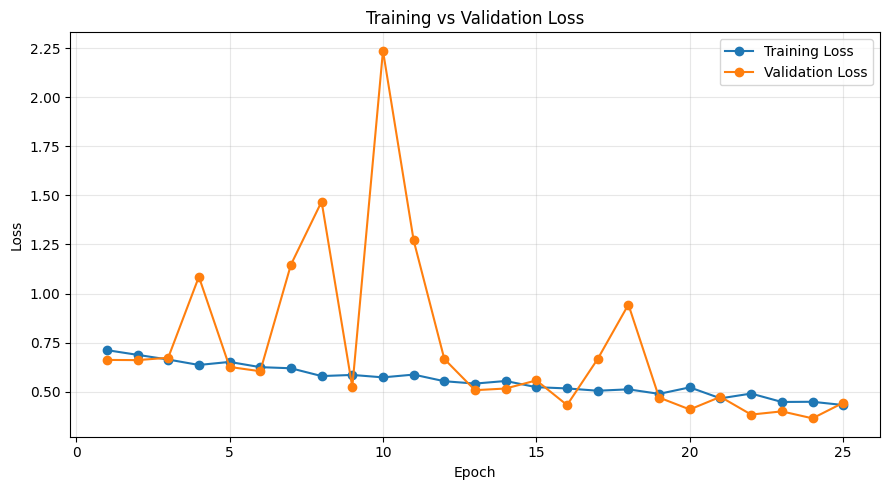

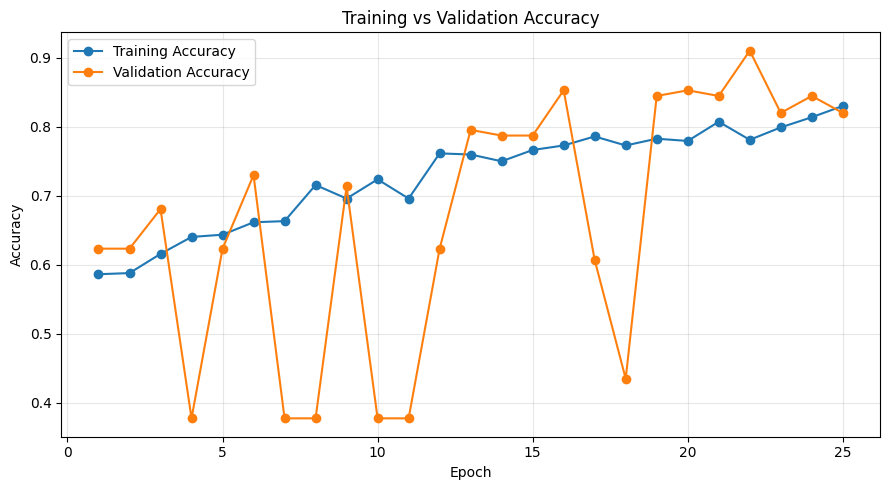

In [44]:

import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

# 1. Loss curves
plt.figure(figsize=(9, 5))
plt.plot(epochs, history["train_loss"], marker="o",
         label="Training Loss")
plt.plot(epochs, history["val_loss"], marker="o",
         label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Accuracy curves
plt.figure(figsize=(9, 5))
plt.plot(epochs, history["train_accuracy"], marker="o",
         label="Training Accuracy")
plt.plot(epochs, history["val_accuracy"], marker="o",
         label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
